# Classifying variable roles from graph paths

The precision matrix gives the linear association between two variables after conditioning on all other selected variables:

$$
\rho_{ij\cdot -ij}=-\frac{\Omega_{ij}}{\sqrt{\Omega_{ii}\Omega_{jj}}},\qquad \Omega=\Sigma^{-1}.
$$

Here, $\Sigma$ is the covariance matrix of the selected variables, $\Omega$ is its inverse, $i$ and $j$ identify two variables, $-ij$ denotes all remaining selected variables, and $\rho_{ij\cdot -ij}$ is their full-order partial correlation.

Row,Field,Value
,String,Any
1,Provider,Kenneth R. French Data Library
2,Archive,49 Industry Portfolios daily archive
3,Return type,Daily value-weighted return
4,Analysis start,2019-01-02
5,Analysis end,2025-12-31
6,Complete dates,1760
7,Selected industries,8
8,Selection rule,Eight named industries fixed before the calculation


Row,First industry,Second industry,Pairwise correlation,Full-order partial correlation,Absolute pairwise correlation,Absolute change
,String,String,Float64,Float64,Float64,Float64
1,Banks,Finance,0.907867,0.643378,0.907867,0.264489
2,Real estate,Finance,0.804775,0.184397,0.804775,0.620378
3,Banks,Real estate,0.792393,0.222084,0.792393,0.570309
4,Banks,Insurance,0.752894,0.226431,0.752894,0.526463
5,Insurance,Finance,0.740571,0.0779242,0.740571,0.662647
6,Finance,Software,0.723952,0.444748,0.723952,0.279204
7,Banks,Oil,0.686455,0.287696,0.686455,0.398758
8,Insurance,Utilities,0.674684,0.371924,0.674684,0.30276
9,Insurance,Real estate,0.641374,-0.00224707,0.641374,0.643621


Row,First industry,Second industry,Pairwise correlation,Full-order partial correlation,Absolute change
,String,String,Float64,Float64,Float64
1,Banks,Finance,0.907867,0.643378,0.264489
2,Real estate,Finance,0.804775,0.184397,0.620378
3,Banks,Real estate,0.792393,0.222084,0.570309
4,Banks,Insurance,0.752894,0.226431,0.526463
5,Insurance,Finance,0.740571,0.0779242,0.662647
6,Finance,Software,0.723952,0.444748,0.279204
7,Banks,Oil,0.686455,0.287696,0.398758
8,Insurance,Utilities,0.674684,0.371924,0.30276
9,Insurance,Real estate,0.641374,-0.00224707,0.643621


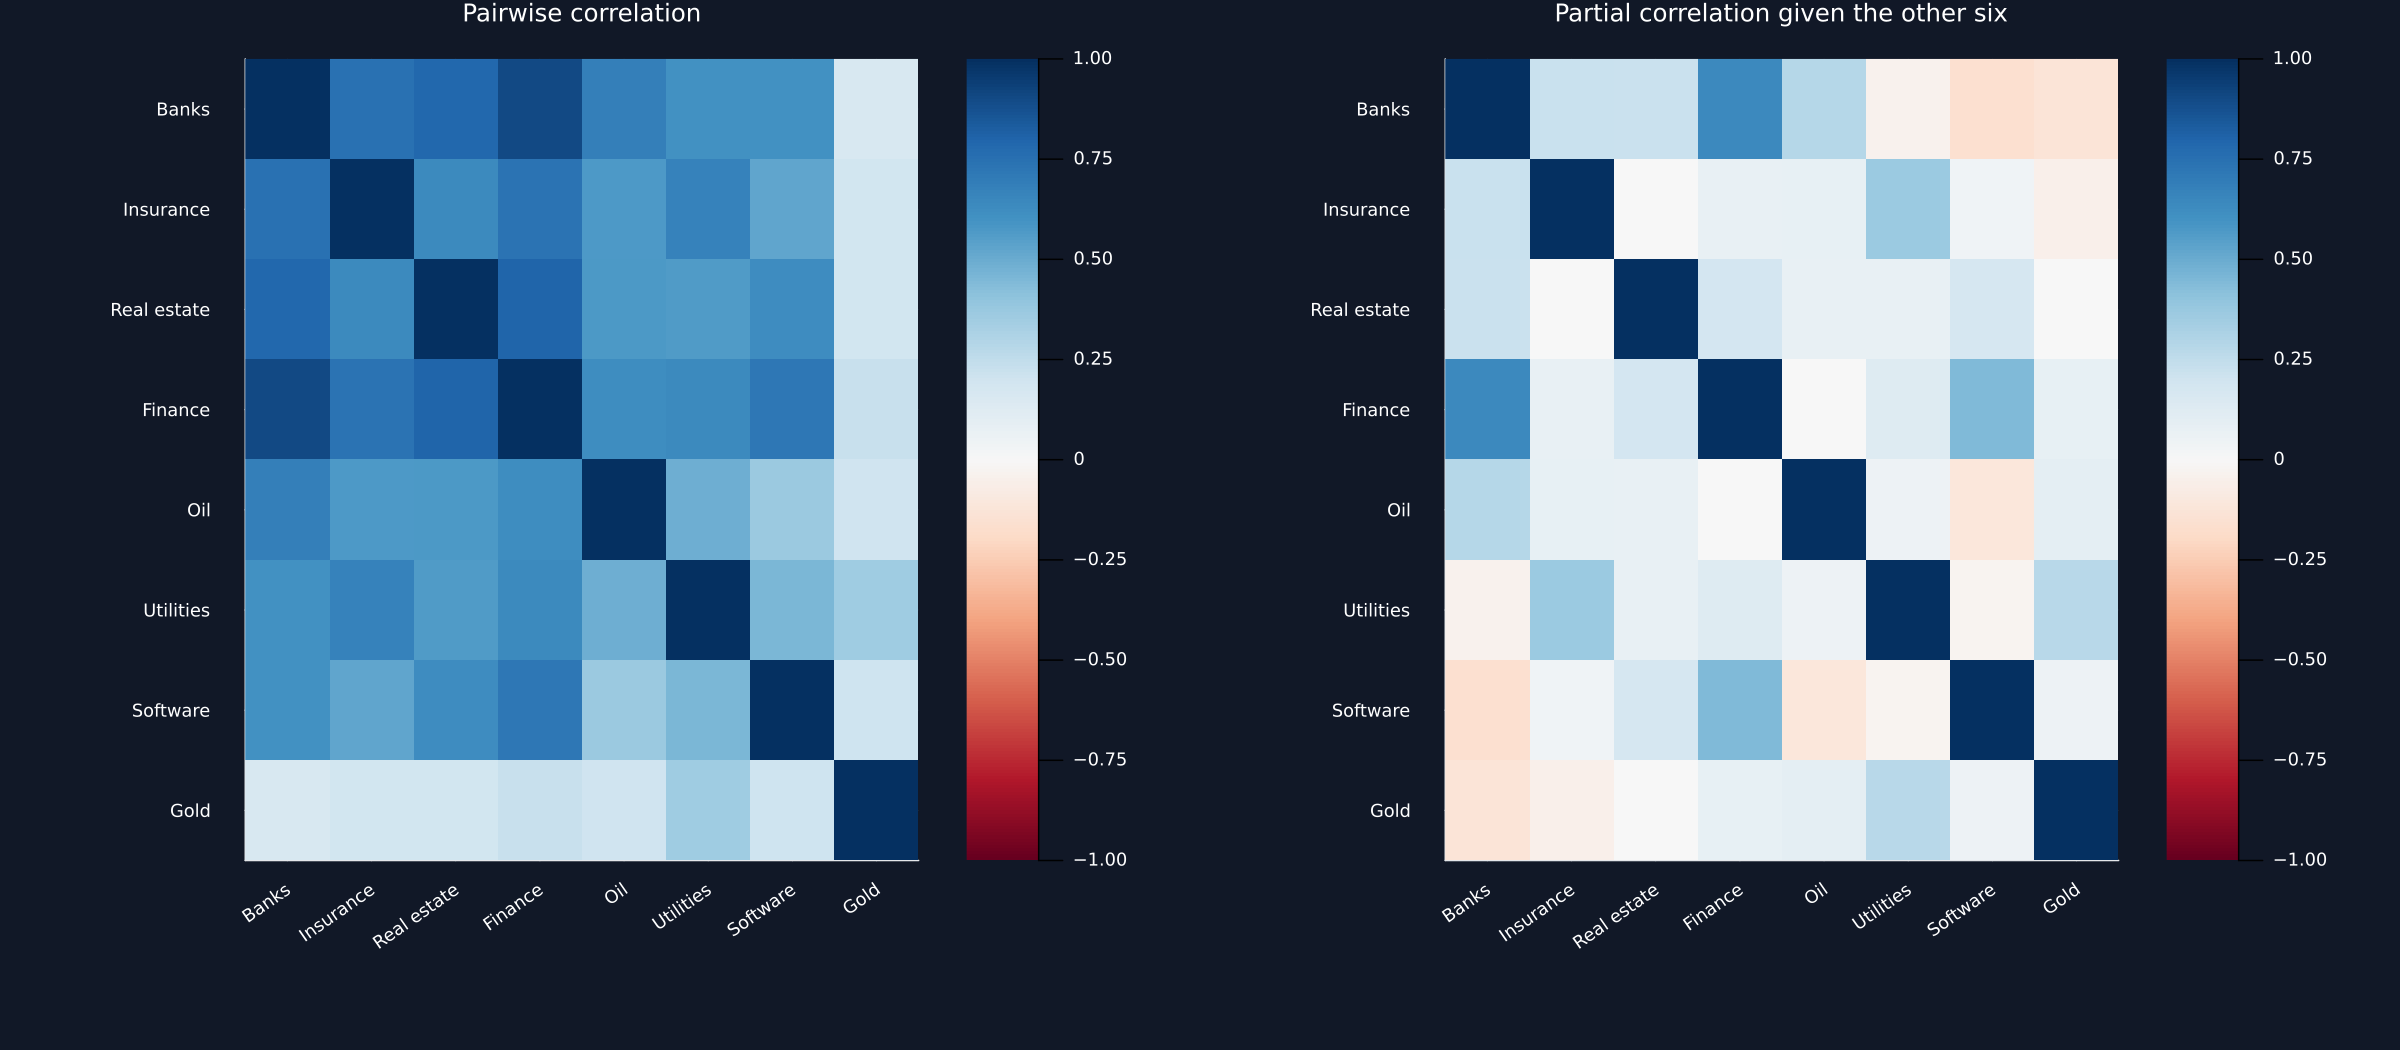

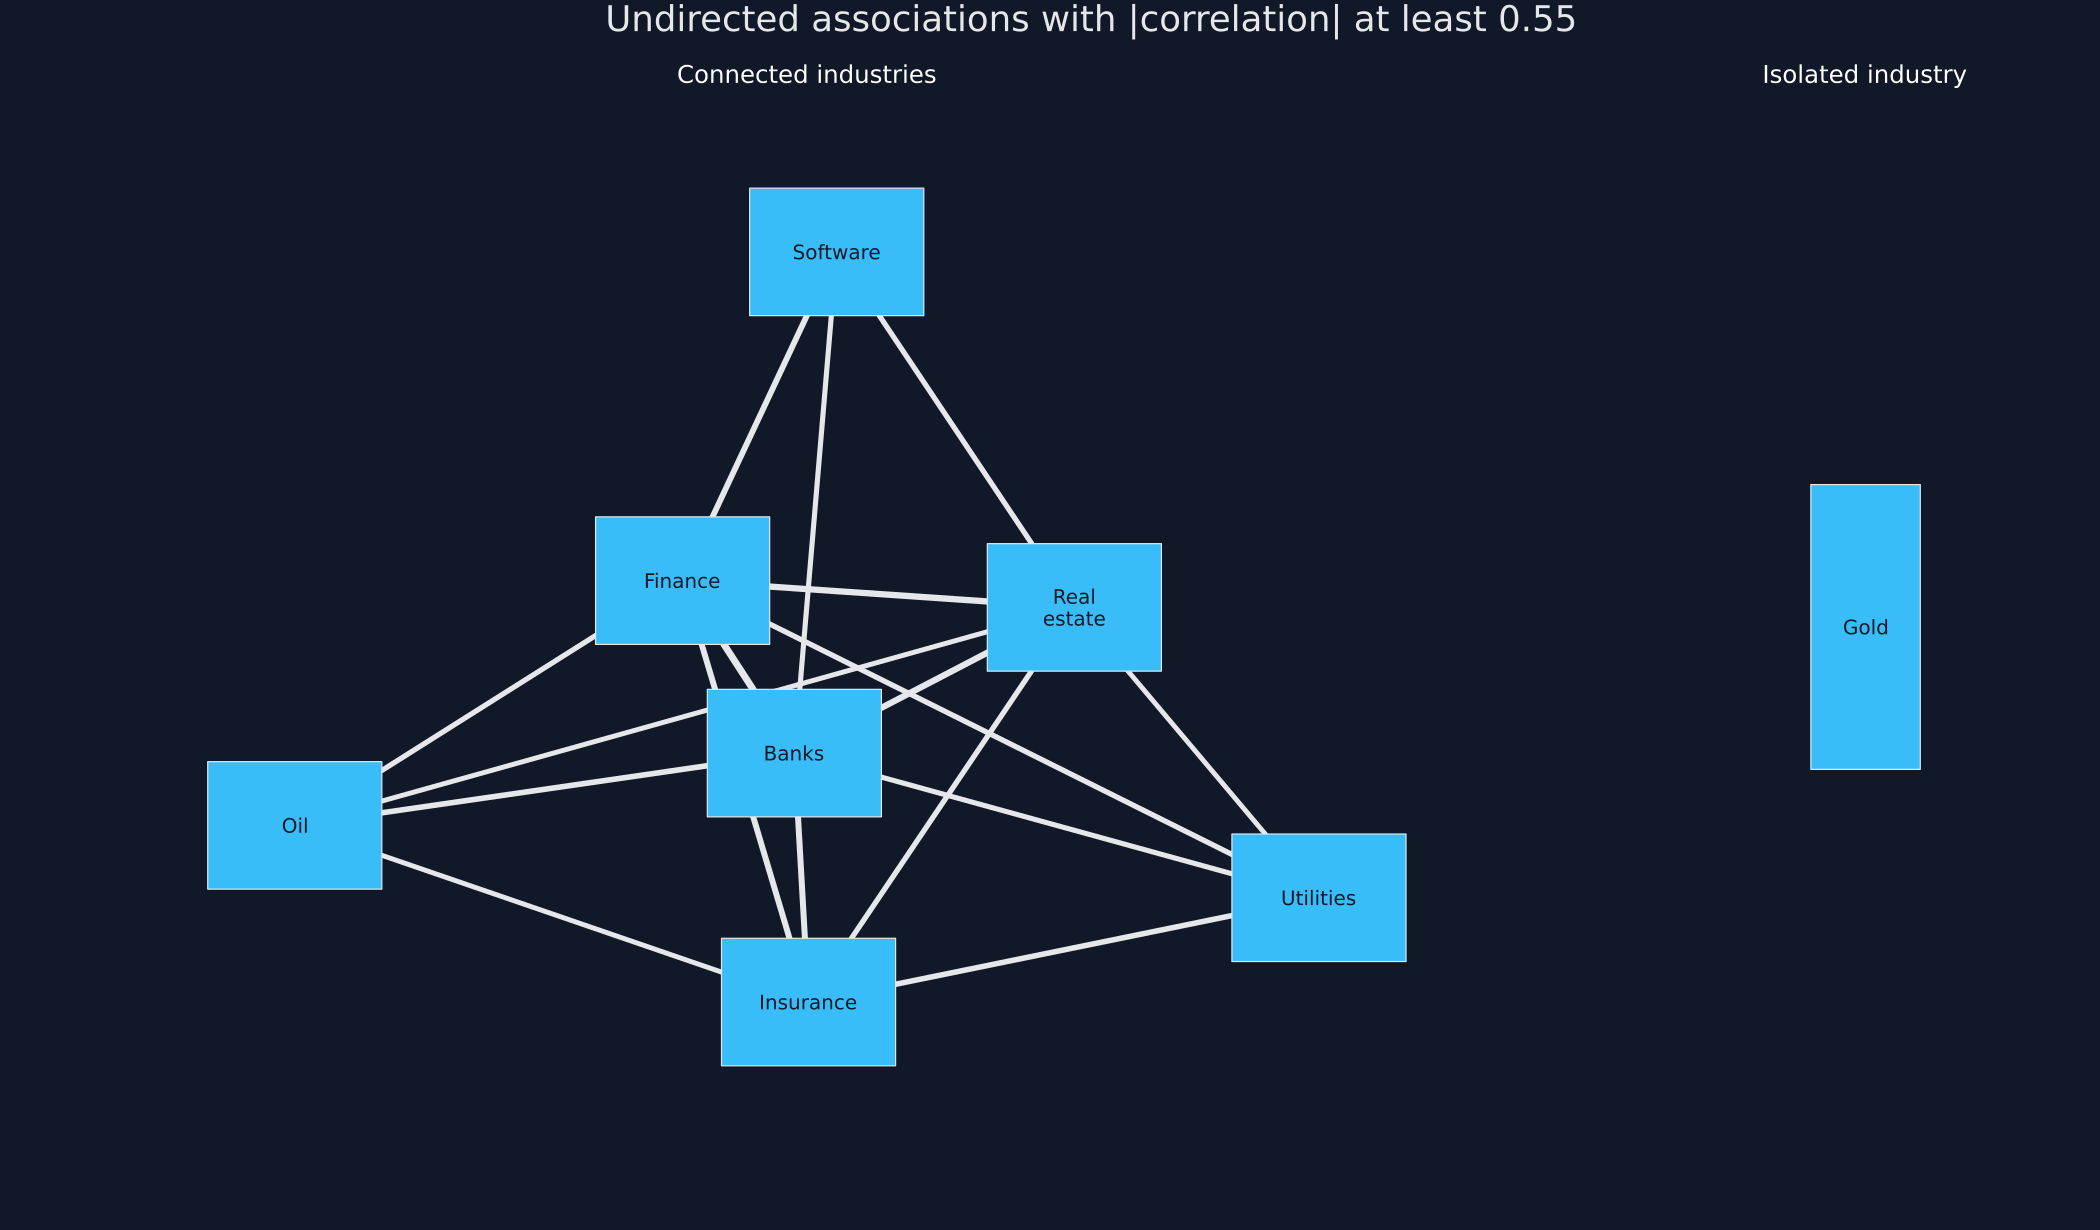

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("01_causal_roles");
using CSV, TOML
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
using RiskLabAI.CausalFactorAnalysis: d_separation
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
input_directory = joinpath("..","data","chapter01_random_inputs")
table(values,name,caption) = save_table(values,paths,name;caption,label="tab:chapter23-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[first_row:last_row-1],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_values .!= -99.99).&(all_values .!= -999.);dims=2))
dates = all_dates[valid]
selected_columns = ["Banks","Insur","RlEst","Fin","Oil","Util","Softw","Gold"]
display_names = ["Banks","Insurance","Real estate","Finance","Oil","Utilities","Software","Gold"]
public_sample = DataFrame(Matrix{Float64}(raw[valid,selected_columns])/100,display_names)
public_provenance = DataFrame("Field"=>["Provider","Archive","Return type","Analysis start","Analysis end","Complete dates","Selected industries","Selection rule"],"Value"=>Any["Kenneth R. French Data Library","49 Industry Portfolios daily archive","Daily value-weighted return",string(first(dates)),string(last(dates)),nrow(public_sample),ncol(public_sample),"Eight named industries fixed before the calculation"])
public_correlation,public_covariance = cor(Matrix(public_sample)),cov(Matrix(public_sample))
precision = inv(public_covariance)
partial_values = -precision./sqrt.(diag(precision)*diag(precision)')
partial_values[diagind(partial_values)] .= 1
association_rows = [(display_names[i],display_names[j],public_correlation[i,j],partial_values[i,j],abs(public_correlation[i,j]),abs(partial_values[i,j]-public_correlation[i,j])) for i in 1:7 for j in i+1:8]
public_association_summary = sort(frame(["First industry","Second industry","Pairwise correlation","Full-order partial correlation","Absolute pairwise correlation","Absolute change"],association_rows),"Absolute pairwise correlation";rev=true)
public_pairwise_partial_comparison = select(first(public_association_summary,12),Not("Absolute pairwise correlation"))
table(public_provenance,"causal_public_data_provenance","Public observations used for the Chapter 23 association example.")
table(public_association_summary,"public_association_summary","Pairwise and full-order partial correlations for the selected public industries.")
table(public_pairwise_partial_comparison,"public_pairwise_partial_comparison","Largest public pairwise correlations and their partial-correlation counterparts.")
for (name,matrix) in [("public_covariance",public_covariance),("public_correlation",public_correlation),("public_partial_correlation",partial_values)]
    save_data(matrix_data(matrix),paths,name)
end
save_data(hcat(DataFrame(Date=dates),public_sample),paths,"public_sample")
save_figure(plot(matrix_panel(public_correlation,display_names,"Pairwise correlation"),matrix_panel(partial_values,display_names,"Partial correlation given the other six");layout=(1,2),size=(1600,700),bottom_margin=22Plots.mm,left_margin=18Plots.mm),paths,"public_correlation_partial_matrices")
threshold = .55
association_rows_selected = public_association_summary[public_association_summary[!,"Absolute pairwise correlation"].>=threshold,:]
association_edges = [(row[1],row[2]) for row in eachrow(association_rows_selected)]
association_graph = DirectedGraph(display_names,association_edges)
adjacency = zeros(8,8)
for row in eachrow(association_rows_selected)
    i,j = findfirst(==(row[1]),display_names),findfirst(==(row[2]),display_names)
    adjacency[i,j] = adjacency[j,i] = row["Absolute pairwise correlation"]
end
network_values = spring_positions(adjacency,primitive_input(input_directory,2303))
network_positions = Dict(name=>Tuple(network_values[i,:]) for (i,name) in enumerate(display_names))
save_data(DataFrame("Industry"=>display_names,"x"=>network_values[:,1],"y"=>network_values[:,2]),paths,"network_positions")
save_data(select(association_rows_selected,["First industry","Second industry","Absolute pairwise correlation"]),paths,"network_edges")
network_labels = Dict(name=>replace(name," "=>"\n") for name in display_names)
connected_nodes = display_names[vec(any(adjacency.>0;dims=2))]
isolated_nodes = setdiff(display_names,connected_nodes)
connected_graph = subgraph(association_graph,connected_nodes)
expanded_positions = Dict(node=>10 .*network_positions[node] for node in connected_nodes)
connected_panel = graph_panel(connected_graph,expanded_positions,"Connected industries";labels=network_labels,directed=false,widths=1 .+4 .*association_rows_selected[!,"Absolute pairwise correlation"])
isolated_graph = DirectedGraph(isolated_nodes,Tuple{String,String}[])
isolated_panel = plot(graph_panel(isolated_graph,Dict(node=>(0.,0.) for node in isolated_nodes),"Isolated industry");xlims=(-.6,.6),ylims=(-.6,.6))
figure = plot(connected_panel,isolated_panel;layout=@layout([a{0.78w} b]),size=(1400,820),plot_title="Undirected associations with |correlation| at least 0.55")
save_figure(figure,paths,"public_association_network")


## Why conditioning screens do not identify causal roles

The change caused by conditioning on one candidate variable is a descriptive association screen:

$$
\Delta_Z=\rho_{XY\cdot Z}-\rho_{XY}.
$$

Here, $X$ is the selected treatment candidate, $Y$ is the selected outcome candidate, $Z$ is one candidate conditioning variable, $\rho_{XY}$ is their pairwise correlation, $\rho_{XY\cdot Z}$ is their partial correlation given $Z$, and $\Delta_Z$ is the resulting change in association rather than a causal-role label.

Row,Candidate variable,Pairwise correlation,Correlation after conditioning,Change,Absolute change
,String,Float64,Float64,Float64,Float64
1,Real estate,0.907867,0.746136,-0.16173,0.16173
2,Insurance,0.907867,0.792063,-0.115804,0.115804
3,Oil,0.907867,0.84279,-0.0650772,0.0650772
4,Utilities,0.907867,0.850611,-0.0572561,0.0572561
5,Software,0.907867,0.854494,-0.0533725,0.0533725
6,Gold,0.907867,0.906433,-0.00143387,0.00143387


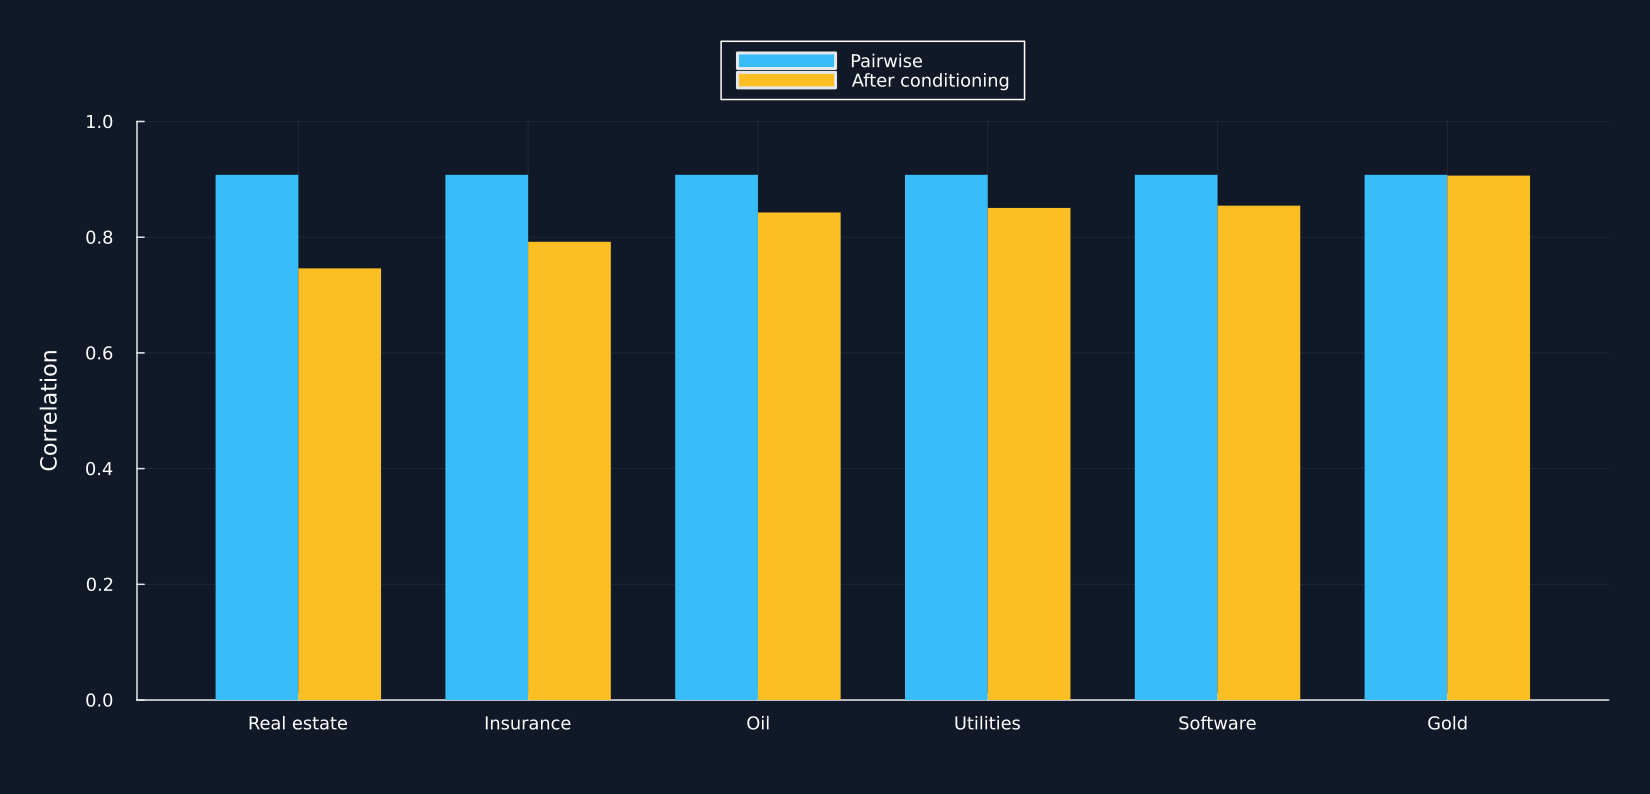

In [2]:
treatment_name,outcome_name = "Banks","Finance"
marginal_value = partial_correlation(public_sample[!,treatment_name],public_sample[!,outcome_name])
conditioning_rows = Tuple[]
for candidate in filter(name->name!=treatment_name && name!=outcome_name,display_names)
    conditional = partial_correlation(public_sample[!,treatment_name],public_sample[!,outcome_name],public_sample[:,[candidate]])
    push!(conditioning_rows,(candidate,marginal_value,conditional,conditional-marginal_value,abs(conditional-marginal_value)))
end
public_conditioning_screen = sort(frame(["Candidate variable","Pairwise correlation","Correlation after conditioning","Change","Absolute change"],conditioning_rows),"Absolute change";rev=true)
table(public_conditioning_screen,"public_conditioning_screen","Association between banks and finance before and after one-variable conditioning.")
figure = bar((1:6).- .18,public_conditioning_screen[!,"Pairwise correlation"];bar_width=.36,color=palette.cyan,linealpha=0,label="Pairwise",xticks=(1:6,public_conditioning_screen[!,"Candidate variable"]),ylabel="Correlation",ylims=(0,1),legend=:outertop,size=(1100,530))
bar!(figure,(1:6).+ .18,public_conditioning_screen[!,"Correlation after conditioning"];bar_width=.36,color=palette.amber,linealpha=0,label="After conditioning")
save_figure(figure,paths,"public_conditioning_screen")


## Role Sets under Arrow Uncertainty

When several candidate graphs remain possible, a variable has a set of admissible roles rather than one established label:

$$
\mathcal R(Z;X,Y,\mathcal G)=\{r_G(Z;X,Y):G\in\mathcal G\}.
$$

Here, $\mathcal G$ is a set of candidate directed acyclic graphs, $G$ is one candidate, $X$ is the treatment candidate, $Y$ is the outcome candidate, $Z$ is the variable being classified, $r_G$ is the role assigned under $G$, and $\mathcal R$ is the resulting role set.

Row,Candidate graph,Insurance role,Directed edges,Acyclic
,String,String,Int64,Bool
1,Insurance as confounder,confounder,3,true
2,Insurance as mediator,mediator,3,true
3,Insurance as collider,collider,3,true


Row,Candidate graph,Maximum covariance error,Smallest residual variance,Largest absolute coefficient
,String,Float64,Float64,Float64
1,Insurance as confounder,1.0842e-19,4.32062e-5,0.936172
2,Insurance as mediator,5.42101e-20,4.32062e-5,0.746068
3,Insurance as collider,2.71051e-20,4.51352e-5,0.837539


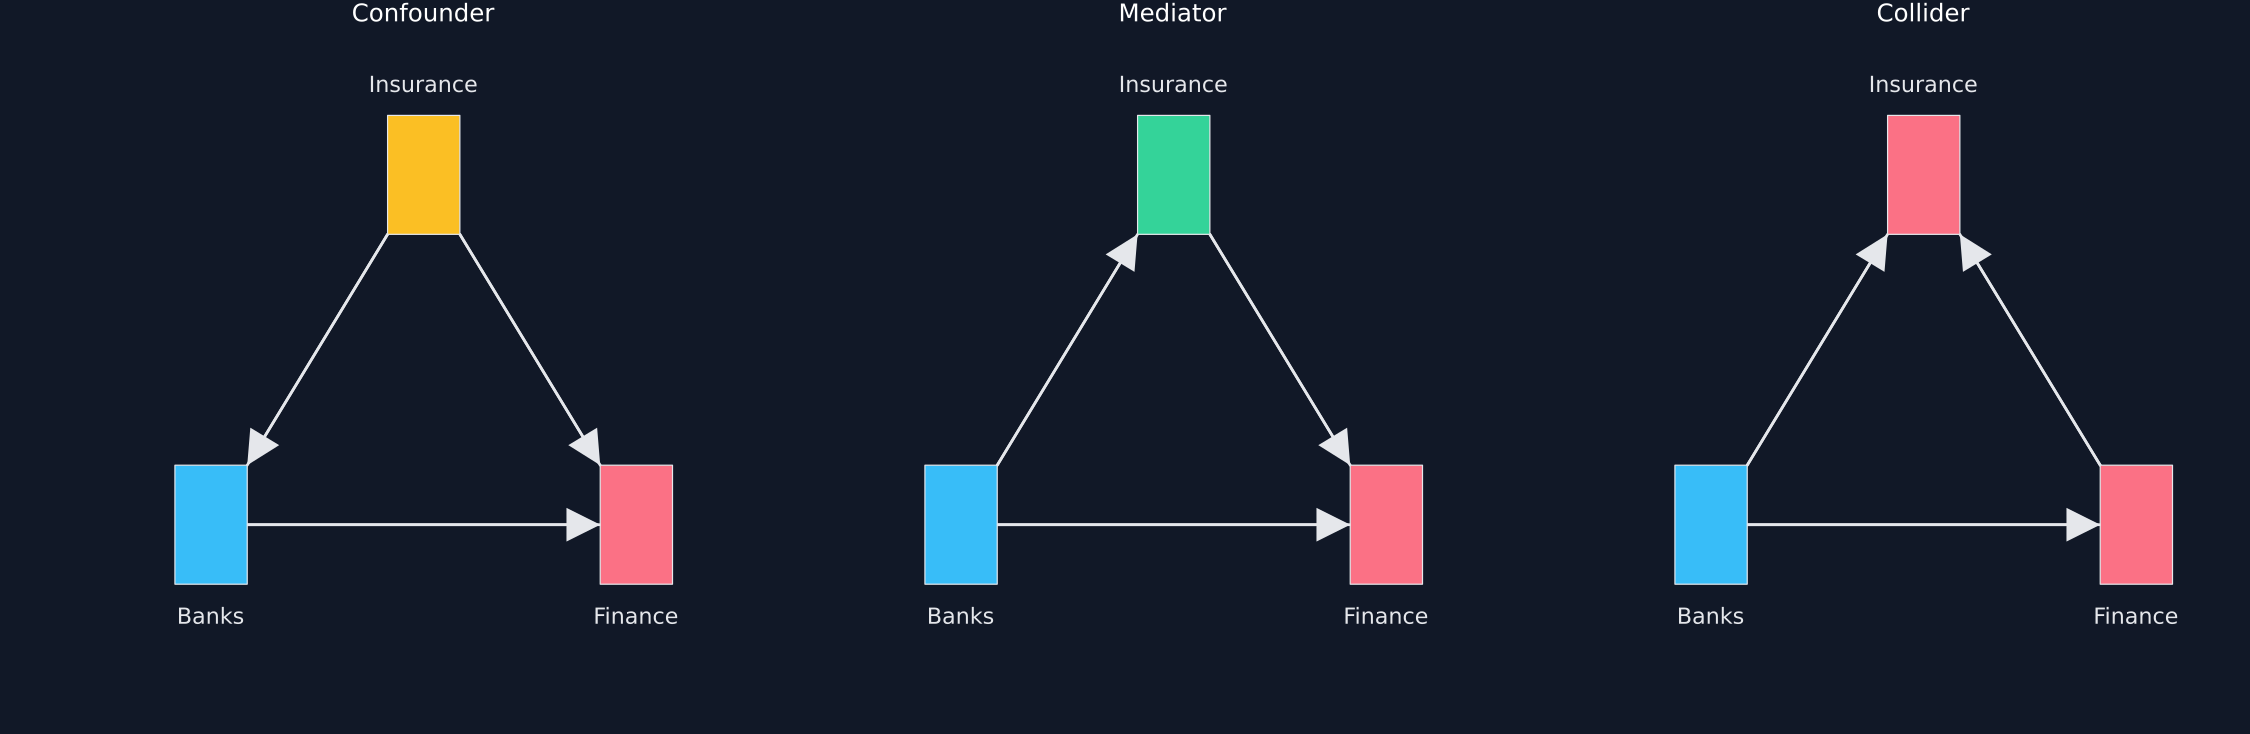

In [3]:
orientation_graphs = ["Insurance as confounder"=>DirectedGraph([("Insurance","Banks"),("Insurance","Finance"),("Banks","Finance")]),"Insurance as mediator"=>DirectedGraph([("Banks","Insurance"),("Insurance","Finance"),("Banks","Finance")]),"Insurance as collider"=>DirectedGraph([("Banks","Insurance"),("Finance","Insurance"),("Banks","Finance")])]
triple_nodes = ["Banks","Insurance","Finance"]
triple_covariance = cov(Matrix(public_sample[:,triple_nodes]))
orientation_rows,reconstruction_rows = Tuple[],Tuple[]
for (index,(name,graph)) in enumerate(orientation_graphs)
    role = classify_causal_role(graph,"Banks","Finance","Insurance")
    coefficients,residual,implied = fit_sem_covariance(triple_covariance,graph,triple_nodes)
    push!(orientation_rows,(name,role,length(graph.edges),acyclic(graph)))
    push!(reconstruction_rows,(name,maximum(abs,implied-triple_covariance),minimum(residual),maximum(abs,coefficients)))
    save_data(matrix_data(coefficients),paths,"orientation_coefficients_"*string(index))
    save_data(DataFrame(variance=residual),paths,"orientation_variances_"*string(index))
end
orientation_role_uncertainty = frame(["Candidate graph","Insurance role","Directed edges","Acyclic"],orientation_rows)
orientation_covariance_reconstruction = frame(["Candidate graph","Maximum covariance error","Smallest residual variance","Largest absolute coefficient"],reconstruction_rows)
table(orientation_role_uncertainty,"orientation_role_uncertainty","Insurance roles under three candidate arrow orientations.")
table(orientation_covariance_reconstruction,"orientation_covariance_reconstruction","Exact covariance representations under the three complete candidate graphs.")
common_positions = Dict("Banks"=>(0.,0.),"Insurance"=>(1.,1.),"Finance"=>(2.,0.))
panels = Plots.Plot[]
for (name,graph) in orientation_graphs
    role = classify_causal_role(graph,"Banks","Finance","Insurance")
    colors = Dict("Banks"=>palette.cyan,"Finance"=>palette.rose,"Insurance"=>role_color(role))
    panel = graph_panel(graph,common_positions,titlecase(role);colors,labels=Dict(node=>"" for node in graph.nodes))
    for node in graph.nodes
        x,y = common_positions[node]
        annotate!(panel,x,y+(node=="Insurance" ? .26 : -.26),text(node,10,palette.text,:center))
    end
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,3),size=(1500,490)),paths,"public_orientation_alternatives")


## Covariance Reconstruction Does Not Choose the Arrows

A linear graph with coefficient matrix $B_G$ and diagonal disturbance covariance $D_G$ implies a covariance matrix through:

$$
\Sigma_G=(I-B_G)^{-1}D_G(I-B_G)^{-\mathsf T}.
$$

Here, $G$ is a candidate graph, $B_G$ contains its parent-to-child coefficients, $D_G$ contains disturbance variances, $I$ is the identity matrix, $-\mathsf T$ denotes inverse transpose, and $\Sigma_G$ is the covariance implied by that candidate graph.

Row,Pair,Windows,Mean,Standard deviation,Minimum,Maximum,First,Last
,String,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,Banks-Finance,1635,0.889771,0.043615,0.76371,0.9814,0.929842,0.803378
2,Banks-Insurance,1635,0.654047,0.158617,0.254159,0.946665,0.598141,0.620784
3,Finance-Insurance,1635,0.634483,0.197085,0.184653,0.95306,0.640855,0.475403


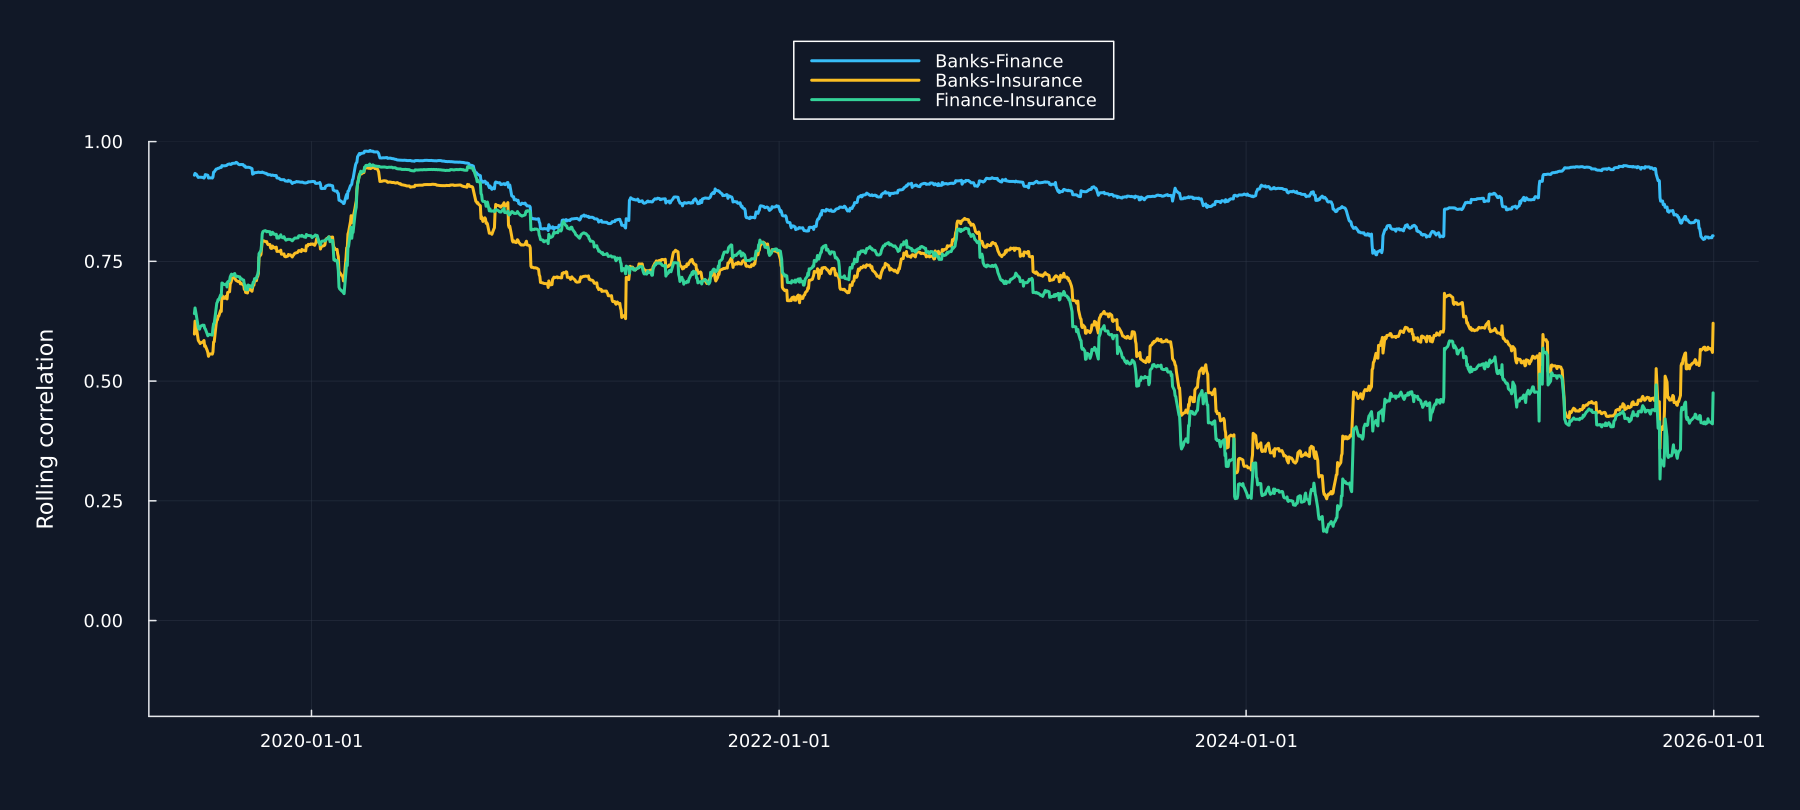

In [4]:
rolling_window = 126
pair_names = ["Banks-Finance","Banks-Insurance","Finance-Insurance"]
pairs = [("Banks","Finance"),("Banks","Insurance"),("Finance","Insurance")]
rolling_values = hcat([[cor(public_sample[(last-rolling_window+1):last,left],public_sample[(last-rolling_window+1):last,right]) for last in rolling_window:nrow(public_sample)] for (left,right) in pairs]...)
rolling_association = DataFrame(rolling_values,pair_names)
rolling_summary_rows = [(name,length(values),mean(values),std(values),minimum(values),maximum(values),first(values),last(values)) for (name,values) in zip(pair_names,eachcol(rolling_values))]
rolling_association_summary = frame(["Pair","Windows","Mean","Standard deviation","Minimum","Maximum","First","Last"],rolling_summary_rows)
table(rolling_association_summary,"rolling_association_summary","Rolling 126-day correlations among banks, insurance, and finance.")
save_data(hcat(DataFrame(Date=dates[rolling_window:end]),rolling_association),paths,"rolling_association")
figure = plot(dates[rolling_window:end],rolling_values;label=permutedims(pair_names),color=permutedims([palette.cyan,palette.amber,palette.green]),ylims=(-.2,1),ylabel="Rolling correlation",legend=:outertop,size=(1200,540))
save_figure(figure,paths,"rolling_public_associations")


## Preserving Unresolved Edges

A graph summary should separate confidently directed edges from edges whose direction remains unresolved:

$$
E=E_{\rightarrow}\cup E_{?},\qquad E_{\rightarrow}\cap E_{?}=\varnothing.
$$

Here, $E$ is the reported edge set, $E_{\rightarrow}$ contains confidently directed edges, $E_{?}$ contains undirected, bidirected, or circle-marked edges, and the empty intersection prevents an unresolved edge from being silently treated as certain.

Row,From,To,Status
,String,String,String
1,A,B,Directed


Row,First node,Second node,Status
,String,String,String
1,A,D,bidirected
2,B,C,undirected
3,C,D,circle


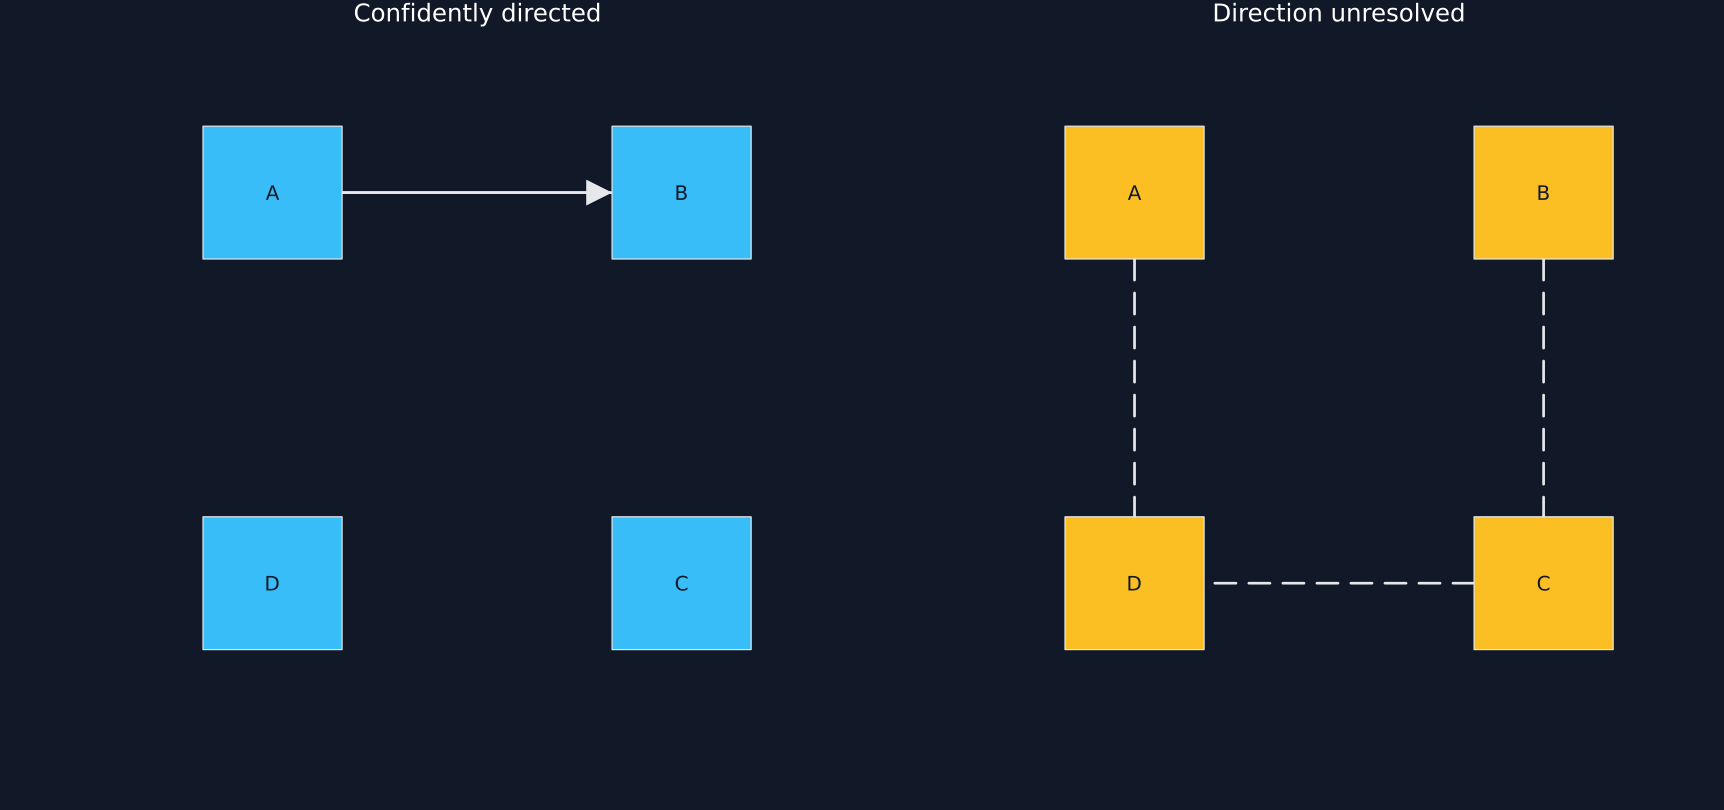

Row,Quantity,Value
,String,Int64
1,Public observations,1760
2,Selected industries,8
3,Industry pairs,28
4,Conditioning candidates,6
5,Candidate arrow orientations,3
6,Rolling windows,1635
7,Directed translated edges,1
8,Unresolved translated edges,3
9,Figures,6


In [5]:
endpoint_names = ["A","B","C","D"]
endpoint_matrix = zeros(4,4)
endpoint_matrix[1,2],endpoint_matrix[2,1] = -1,1
endpoint_matrix[2,3],endpoint_matrix[3,2] = -1,-1
endpoint_matrix[1,4],endpoint_matrix[4,1] = 1,1
endpoint_matrix[3,4],endpoint_matrix[4,3] = 2,1
certain_graph,ambiguous_edges,bidirected_edges = CausalNotebookTools._endpoint_matrix_to_digraph(endpoint_matrix,endpoint_names)
endpoint_translation = frame(["From","To","Status"],[(left,right,"Directed") for (left,right) in ordered_edges(certain_graph)])
ambiguous_edge_table = frame(["First node","Second node","Status"],ambiguous_edges)
table(endpoint_translation,"endpoint_translation","Confidently directed edges retained from the endpoint matrix.")
table(ambiguous_edge_table,"ambiguous_edge_table","Edges retained as unresolved rather than assigned a direction.")
endpoint_positions = Dict("A"=>(0.,1.),"B"=>(1.,1.),"C"=>(1.,0.),"D"=>(0.,0.))
ambiguous_graph = DirectedGraph(endpoint_names,[(left,right) for (left,right,_) in ambiguous_edges])
save_figure(plot(graph_panel(certain_graph,endpoint_positions,"Confidently directed"),graph_panel(ambiguous_graph,endpoint_positions,"Direction unresolved";directed=false,dashed=true,colors=Dict(node=>palette.amber for node in endpoint_names));layout=(1,2),size=(1150,540)),paths,"endpoint_direction_uncertainty")
path_evidence_section_summary = DataFrame("Quantity"=>["Public observations","Selected industries","Industry pairs","Conditioning candidates","Candidate arrow orientations","Rolling windows","Directed translated edges","Unresolved translated edges","Figures","Generated tables"],"Value"=>[nrow(public_sample),ncol(public_sample),nrow(public_association_summary),nrow(public_conditioning_screen),length(orientation_graphs),nrow(rolling_association),length(certain_graph.edges),length(ambiguous_edges),6,10])
table(path_evidence_section_summary,"path_evidence_section_summary","Section 23.3 numerical summary.")


## Tests

In [6]:
@assert size(public_sample)==(1760,8)
@assert public_correlation≈public_correlation'
@assert diag(public_correlation)≈ones(8)
@assert partial_values≈partial_values'
@assert diag(partial_values)≈ones(8)
@assert nrow(public_association_summary)==28
@assert nrow(public_conditioning_screen)==6
@assert Set(orientation_role_uncertainty[!,"Insurance role"])==Set(["confounder","mediator","collider"])
@assert all(orientation_role_uncertainty.Acyclic)
@assert maximum(orientation_covariance_reconstruction[!,"Maximum covariance error"])<1e-12
@assert minimum(orientation_covariance_reconstruction[!,"Smallest residual variance"])>0
@assert nrow(rolling_association)==nrow(public_sample)-rolling_window+1
@assert all(isfinite,rolling_values)
@assert certain_graph.edges==[("A","B")]
@assert Set(last.(ambiguous_edges))==Set(["undirected","bidirected","circle"])
@assert bidirected_edges==[("A","D")]
@assert nrow(path_evidence_section_summary)==10
assert_artifacts(["public_correlation_partial_matrices","public_association_network","public_conditioning_screen","public_orientation_alternatives","rolling_public_associations","endpoint_direction_uncertainty"],["causal_public_data_provenance","public_association_summary","public_pairwise_partial_comparison","public_conditioning_screen","orientation_role_uncertainty","orientation_covariance_reconstruction","rolling_association_summary","endpoint_translation","ambiguous_edge_table","path_evidence_section_summary"])
nothing
